In [1]:
import tensorflow as tf 
import numpy as np 
import matplotlib.pyplot as plt 
from tensorflow.keras import regularizers
from tensorflow.keras import layers,models
from tensorflow.keras.layers import Dense,Dropout,Flatten
from tensorflow.keras.initializers import GlorotNormal,HeNormal

In [2]:
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.cifar10.load_data()

In [3]:
x_train=x_train/255.0
x_test=x_test/255.0

In [4]:
basemodel=models.Sequential([
    layers.Flatten(input_shape=(32,32,3)),
    layers.Dense(256,activation='relu'),
    layers.Dense(128,activation='relu'),
    layers.Dense(10,activation='softmax')
])

c:\Users\VIVEK V\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
basemodel.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [6]:
basehistory=basemodel.fit(x_train,y_train,epochs=3,validation_data=(x_test,y_test))

Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 24s 14ms/step - accuracy: 0.3271 - loss: 1.8625 - val_accuracy: 0.3771 - val_loss: 1.7128
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.3968 - loss: 1.6765 - val_accuracy: 0.4018 - val_loss: 1.6683
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.4268 - loss: 1.5981 - val_accuracy: 0.4333 - val_loss: 1.5924


In [7]:
xavier_model=models.Sequential([
    layers.Flatten(input_shape=(32,32,3)),
    layers.Dense(256,activation='relu',kernel_initializer=GlorotNormal()),
    layers.Dense(128,activation='relu',kernel_initializer=GlorotNormal()),
    layers.Dense(10,activation='softmax')
])

c:\Users\VIVEK V\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [8]:
kaiming_model=models.Sequential([
    layers.Flatten(input_shape=(32,32,3)),
    layers.Dense(256,activation='relu',kernel_initializer=HeNormal()),
    layers.Dense(128,activation='relu',kernel_initializer=HeNormal()),
    layers.Dense(10,activation='softmax')
])

In [9]:
model_dropout=models.Sequential([
    layers.Flatten(input_shape=(32,32,3)),
    layers.Dense(256,activation='relu'),
    Dropout(0.5),
    layers.Dense(128,activation='relu'),
    Dropout(0.5),
    layers.Dense(10,activation='softmax')
])

In [ ]:
model_l1=models.Sequential([
    layers.Flatten(input_shape=(32,32,3)),
    layers.Dense(256,activation='relu',kernel_regularizer=regularizers.L1(0.0001)),
    layers.Dense(128,activation='relu',kernel_regularizer=regularizers.L1(0.0001)),
    layers.Dense(10,activation='softmax')
])

In [11]:
model_l2=models.Sequential([
    layers.Flatten(input_shape=(32,32,3)),
    layers.Dense(256,activation='relu',kernel_regularizer=regularizers.L2(0.0001)),
    layers.Dense(128,activation='relu',kernel_regularizer=regularizers.L2(0.0001)),
    layers.Dense(10,activation='softmax')
])

In [12]:
xavier_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [13]:
kaiming_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [14]:
model_dropout.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [15]:
model_l1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [16]:
model_l2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [17]:
xavier_his=kaiming_model.fit(x_train,y_train,epochs=3,validation_data=(x_test,y_test))

Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.3255 - loss: 1.8721 - val_accuracy: 0.3886 - val_loss: 1.7125
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.3934 - loss: 1.6870 - val_accuracy: 0.4094 - val_loss: 1.6621
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 35s 22ms/step - accuracy: 0.4219 - loss: 1.6095 - val_accuracy: 0.4047 - val_loss: 1.6616


In [18]:
kaiming_modelhistory=kaiming_model.fit(x_train,y_train,epochs=3,validation_data=(x_test,y_test))

Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 27s 17ms/step - accuracy: 0.4386 - loss: 1.5621 - val_accuracy: 0.4556 - val_loss: 1.5373
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 53s 23ms/step - accuracy: 0.4540 - loss: 1.5204 - val_accuracy: 0.4534 - val_loss: 1.5309
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 34s 21ms/step - accuracy: 0.4669 - loss: 1.4929 - val_accuracy: 0.4536 - val_loss: 1.5317


In [19]:
model_dropout_hist=model_dropout.fit(x_train,y_train,epochs=3,validation_data=(x_test,y_test))

Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 29s 14ms/step - accuracy: 0.1350 - loss: 2.2430 - val_accuracy: 0.1862 - val_loss: 2.1244
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 36s 10ms/step - accuracy: 0.1569 - loss: 2.1766 - val_accuracy: 0.2129 - val_loss: 2.1047
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.1624 - loss: 2.1686 - val_accuracy: 0.2115 - val_loss: 2.1110


In [20]:
model_l1_hist=model_l1.fit(x_train,y_train,epochs=3,validation_data=(x_test,y_test))

Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 26s 15ms/step - accuracy: 0.3253 - loss: 2.2878 - val_accuracy: 0.3692 - val_loss: 1.9132
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 34s 22ms/step - accuracy: 0.3757 - loss: 1.9003 - val_accuracy: 0.3708 - val_loss: 1.9309
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.3939 - loss: 1.8260 - val_accuracy: 0.3820 - val_loss: 1.8529


In [21]:
model_l2_hist=model_l2.fit(x_train,y_train,epochs=3,validation_data=(x_test,y_test))

Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - accuracy: 0.3287 - loss: 1.8928 - val_accuracy: 0.4049 - val_loss: 1.6989
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.3989 - loss: 1.6974 - val_accuracy: 0.4051 - val_loss: 1.6552
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 34s 22ms/step - accuracy: 0.4277 - loss: 1.6266 - val_accuracy: 0.4269 - val_loss: 1.6384


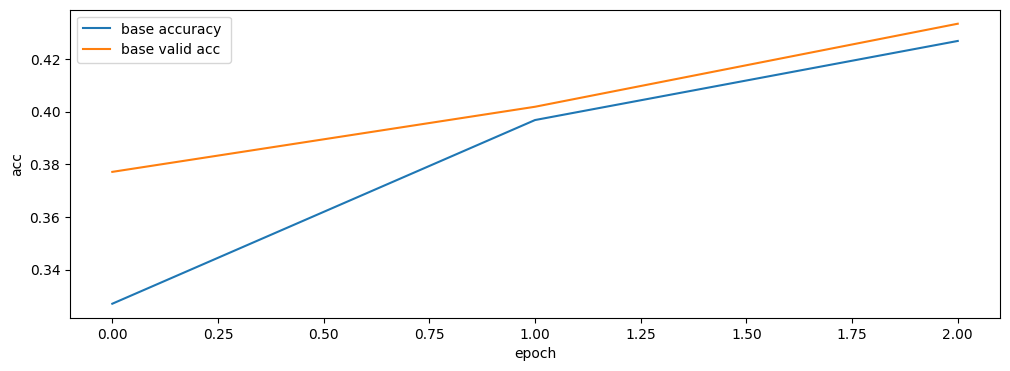

In [22]:
plt.figure(figsize=(12,4))
plt.plot(basehistory.history['accuracy'],label='base accuracy')
plt.plot(basehistory.history['val_accuracy'],label='base valid acc ')
plt.xlabel('epoch')
plt.ylabel('acc')
plt.legend()

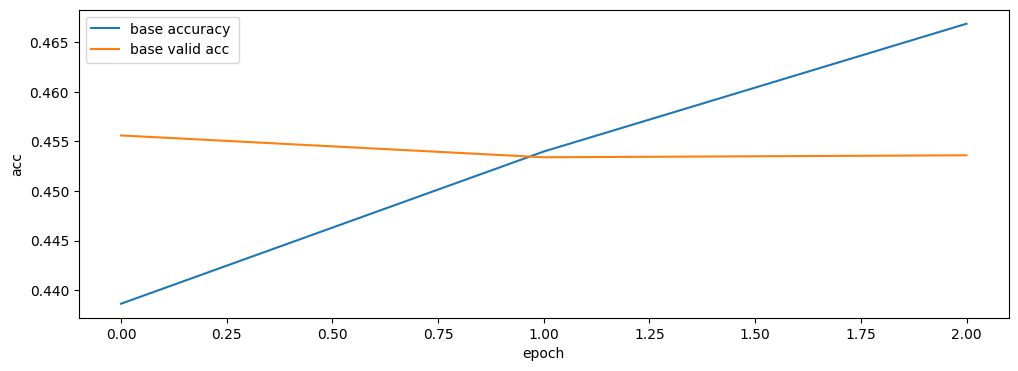

In [23]:
plt.figure(figsize=(12,4))
plt.plot(kaiming_modelhistory.history['accuracy'],label='base accuracy')
plt.plot(kaiming_modelhistory.history['val_accuracy'],label='base valid acc ')
plt.xlabel('epoch')
plt.ylabel('acc')
plt.legend()

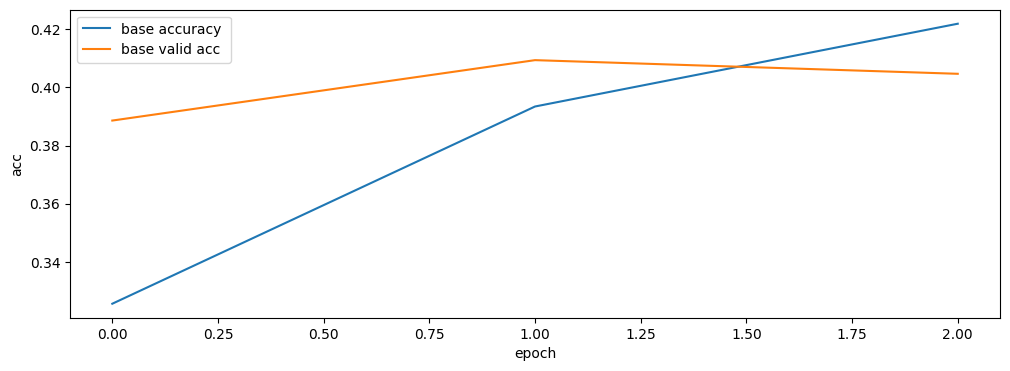

In [24]:
plt.figure(figsize=(12,4))
plt.plot(xavier_his.history['accuracy'],label='base accuracy')
plt.plot(xavier_his.history['val_accuracy'],label='base valid acc ')
plt.xlabel('epoch')
plt.ylabel('acc')
plt.legend()

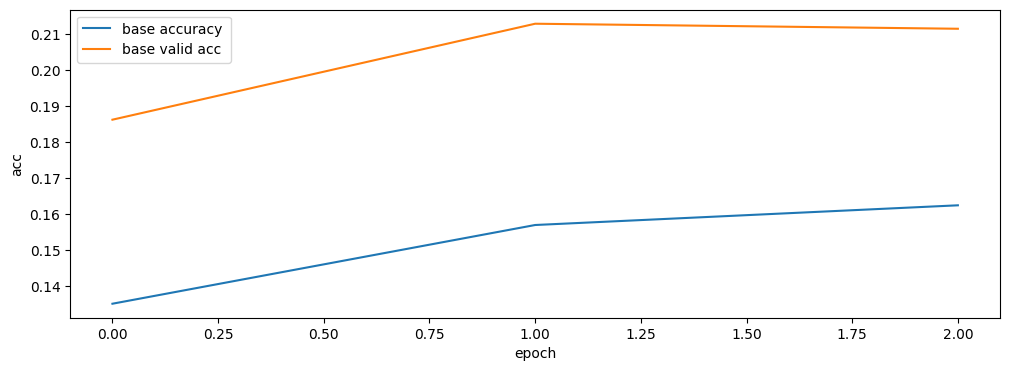

In [25]:
plt.figure(figsize=(12,4))
plt.plot(model_dropout_hist.history['accuracy'],label='base accuracy')
plt.plot(model_dropout_hist.history['val_accuracy'],label='base valid acc ')
plt.xlabel('epoch')
plt.ylabel('acc')
plt.legend()

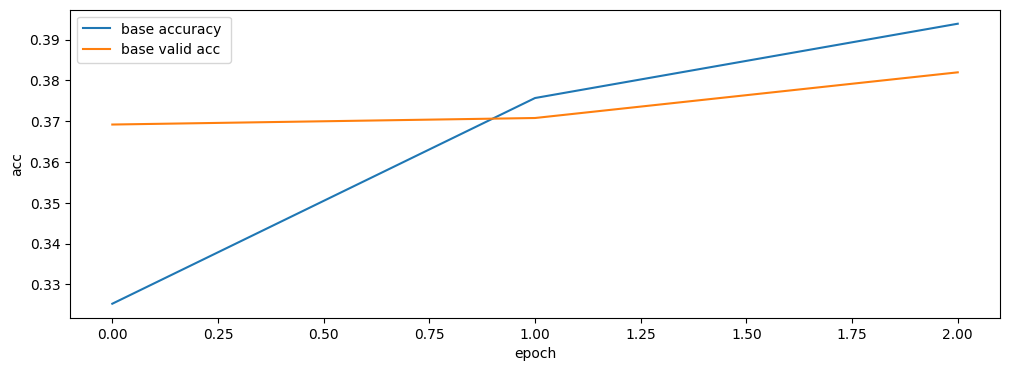

In [26]:
plt.figure(figsize=(12,4))
plt.plot(model_l1_hist.history['accuracy'],label='base accuracy')
plt.plot(model_l1_hist.history['val_accuracy'],label='base valid acc ')
plt.xlabel('epoch')
plt.ylabel('acc')
plt.legend()

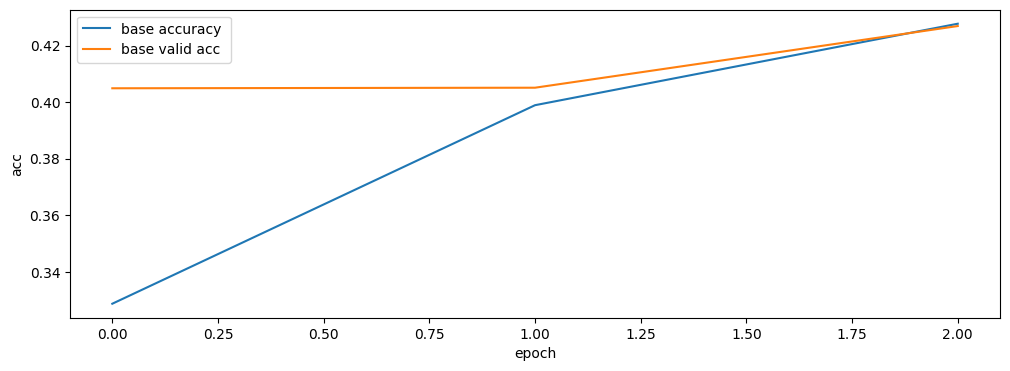

In [27]:
plt.figure(figsize=(12,4))
plt.plot(model_l2_hist.history['accuracy'],label='base accuracy')
plt.plot(model_l2_hist.history['val_accuracy'],label='base valid acc ')
plt.xlabel('epoch')
plt.ylabel('acc')
plt.legend()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


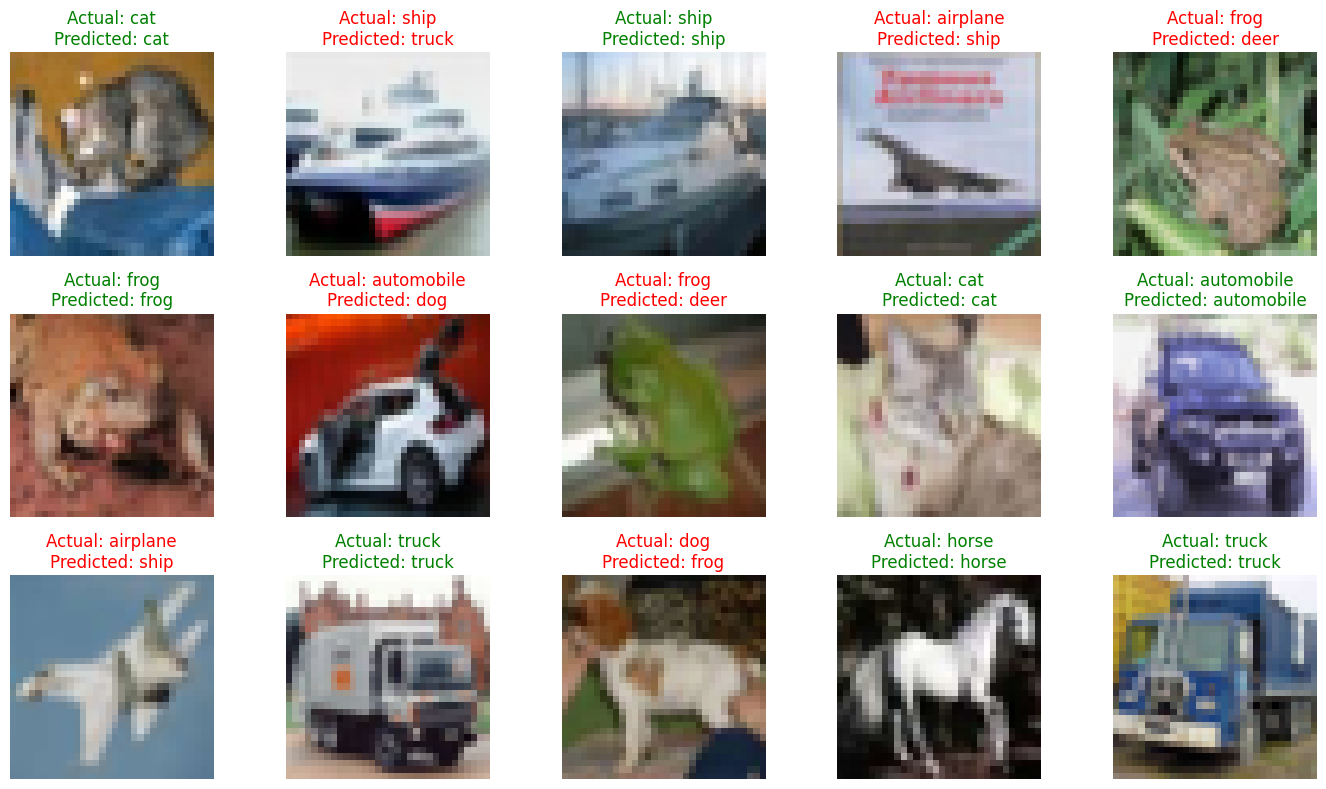

In [32]:

import matplotlib.pyplot as plt
import numpy as np

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Predict images
predictions = basemodel.predict(x_test)

# Get predicted labels
predicted_labels = np.argmax(predictions, axis=1)

# Display 10 images
plt.figure(figsize=(14, 8))

for i in range(15):
    plt.subplot(3, 5, i+1)

    plt.imshow(x_test[i])

    actual = class_names[y_test[i][0]]
    predicted = class_names[predicted_labels[i]]

    if actual == predicted:
        colour = 'green'
    else:
        colour = 'red'

    plt.title(f"Actual: {actual}\nPredicted: {predicted}", color=colour)
    plt.axis('off')

plt.tight_layout()
plt.show()
